# Modeling

We train six models: three architectures × two feature sets.

| | price only (`close`) | price + volume (`close_volume`) |
|---|---|---|
| **LSTM** (main model) | A | B |
| **GRU** | C | D |
| **1D-CNN** | E | F |

Each run saves its model, scalers and metadata to `artifacts/<run>/`. We judge the runs on the validation set here; the test set is kept for the next notebook.

[`docs/03_deep_learning_models.md`](../docs/03_deep_learning_models.md)

In [1]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs
if os.name == "nt":  # Windows: expose the conda env's CUDA/cuDNN DLLs so TensorFlow can find the GPU
    os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

import config
from src.models import build_model, build_lstm, build_gru, build_cnn1d, compile_model
from src.train import train_model
from src.notebook import show_source
from src import plotting

plotting.set_plot_style()
print("TensorFlow", tf.__version__, "| GPUs visible:", tf.config.list_physical_devices("GPU") or "none (CPU training)")

TensorFlow 2.22.0-rc0 | GPUs visible: none (CPU training)


## Building the models

In [3]:
""" LSTM Model """
show_source(build_lstm)


<details>
<summary>View implementation of <code>build_lstm</code></summary>

```python
def build_lstm(
    input_shape: Tuple[int, int],
    learning_rate: float = config.LEARNING_RATE,
    dropout: float = config.DROPOUT,
) -> keras.Model:
    """
    LSTM
    """
    model = keras.Sequential([
            layers.Input(shape=input_shape),
            layers.LSTM(64),
            layers.Dropout(dropout),
            layers.Dense(1)
        ],
            name="lstm")
    return compile_model(model, learning_rate)

```

</details>


In [4]:
""" GRU Model """
show_source(build_gru)


<details>
<summary>View implementation of <code>build_gru</code></summary>

```python
def build_gru(
    input_shape: Tuple[int, int],
    learning_rate: float = config.LEARNING_RATE,
    dropout: float = config.DROPOUT,
) -> keras.Model:
    """
    GRU
    """
    model = keras.Sequential([
            layers.Input(shape=input_shape),
            layers.GRU(64),
            layers.Dropout(dropout),
            layers.Dense(1)
        ],
            name="gru")
    return compile_model(model, learning_rate)

```

</details>


In [5]:
""" 1D Convolutional network Model """
show_source(build_cnn1d)


<details>
<summary>View implementation of <code>build_cnn1d</code></summary>

```python
def build_cnn1d(
    input_shape: Tuple[int, int],
    learning_rate: float = config.LEARNING_RATE,
    dropout: float = config.DROPOUT,
) -> keras.Model:
    """
    1D Convolutional network
    """
    model = keras.Sequential([
            layers.Input(shape=input_shape),
            layers.Conv1D(64, kernel_size=5, activation="relu"),
            layers.GlobalMaxPooling1D(),
            layers.Dropout(dropout),
            layers.Dense(1)
        ],
            name="cnn")
    return compile_model(model, learning_rate)

```

</details>


In [6]:
""" Model Builder """
show_source(build_cnn1d)


<details>
<summary>View implementation of <code>build_cnn1d</code></summary>

```python
def build_cnn1d(
    input_shape: Tuple[int, int],
    learning_rate: float = config.LEARNING_RATE,
    dropout: float = config.DROPOUT,
) -> keras.Model:
    """
    1D Convolutional network
    """
    model = keras.Sequential([
            layers.Input(shape=input_shape),
            layers.Conv1D(64, kernel_size=5, activation="relu"),
            layers.GlobalMaxPooling1D(),
            layers.Dropout(dropout),
            layers.Dense(1)
        ],
            name="cnn")
    return compile_model(model, learning_rate)

```

</details>


## Compiling the models

In [7]:
""" Compile Models """
show_source(compile_model)


<details>
<summary>View implementation of <code>compile_model</code></summary>

```python
def compile_model(model: keras.Model, learning_rate: float = config.LEARNING_RATE) -> keras.Model:
    """
    Attach the optimizer, loss and metrics to a model.

    Adam  : adaptive optimizer; works well with default settings.
    Huber : behaves like MSE for small errors and like MAE for large ones,
            so a few extreme market days (crashes, earnings jumps) do not
            dominate training the way they would with plain MSE.
    MAE   : mean absolute error, an easy-to-read metric that is tracked but not optimized.
    """
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.Huber(delta=1.0),
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

```

</details>


## Inspect the architectures before training
`summary()` shows every layer, its output shape (`None` is the batch size) and its number of trainable parameters.

In [8]:
for name in config.MODEL_NAMES:
    build_model(name, input_shape=(config.LOOKBACK, 3)).summary()
    print()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,473 (68.25 KB)

 Trainable params: 17,473 (68.25 KB)

 Non-trainable params: 0 (0.00 B)

...

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 56, 64)         │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

Model Parameters:

- The LSTM has the most parameters.
- The GRU has has fewer parameters. 
- The CNN is the smallest.

In [9]:
pd.Series({k: getattr(config, k) for k in
           ["START_DATE", "LOOKBACK", "TARGET_MODE", "EPOCHS", "BATCH_SIZE", "LEARNING_RATE", "DROPOUT", "PATIENCE", "SEED"]}
          ).to_frame("value")

,value
START_DATE,2010-01-04
LOOKBACK,60
TARGET_MODE,price
EPOCHS,100
BATCH_SIZE,32
LEARNING_RATE,0.001
DROPOUT,0.2
PATIENCE,10
SEED,42


Training uses three callbacks (see `src/train.py`):
- **EarlyStopping:** stops when validation loss hasn't improved for `PATIENCE` epochs, and restores the best weights.
- **ReduceLROnPlateau:** halves the learning rate when progress stalls.
- **ModelCheckpoint:** saves the best model so far to disk.

## Experiment A: LSTM, price only

findfont: Failed to find font weight semibold for Helvetica, now using 700.


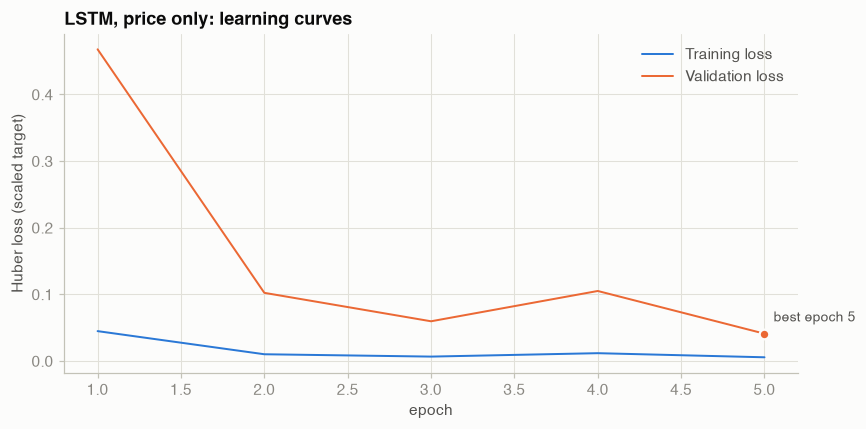

In [10]:
results = {}  # Saved model results will be loaded here; do not retrain.
import json
with open(PROJECT_ROOT / "artifacts/lstm_close_price-target/history.json") as f:

    lstm_close_history = json.load(f)

plotting.plot_history(
    lstm_close_history,
    "LSTM, price only: learning curves"
)
plt.show()

**Reading learning curves**
- Both curves go down, then flatten: the model learned what it could.
- Training loss keeps falling while validation loss rises: **overfitting**, i.e. memorizing noise from the training period.
- Validation loss is lowest after very few epochs: the signal is weak, and the model quickly settles on predicting roughly the average return.

## Experiment B: LSTM, price + volume

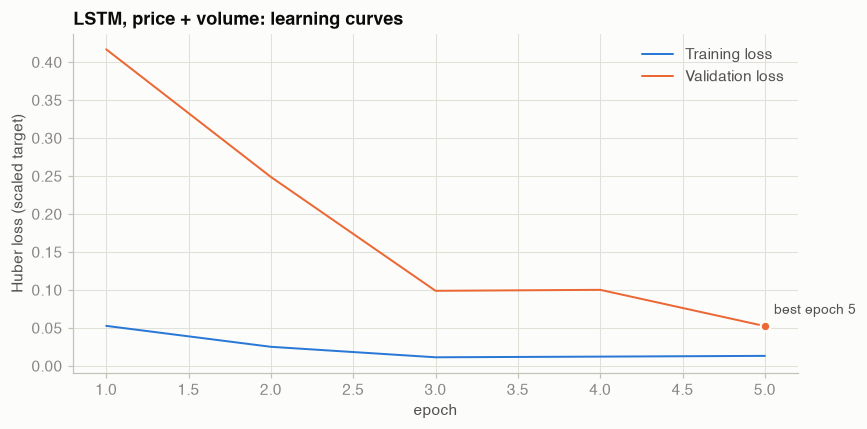

In [11]:
import json
with open(PROJECT_ROOT / "artifacts/lstm_close_volume_price-target/history.json") as f:

    lstm_history = json.load(f)

plotting.plot_history(lstm_history, "LSTM, price + volume: learning curves")
plt.show()

## Experiments C-F: GRU and 1D-CNN
Same data and training loop; only the architecture changes.

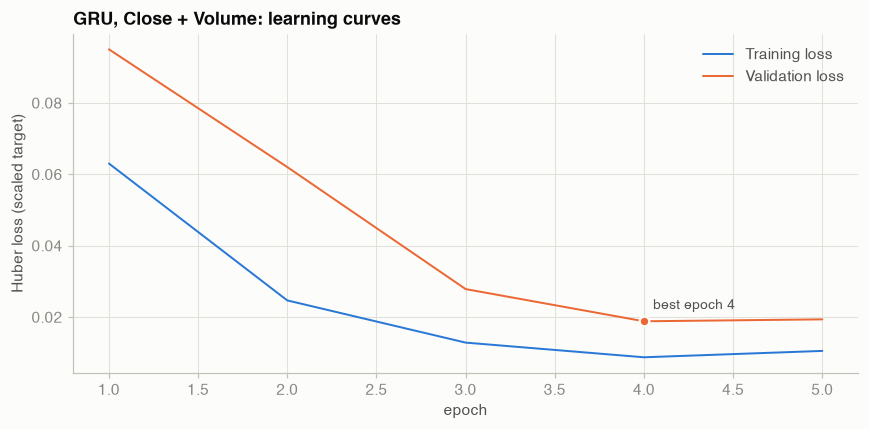

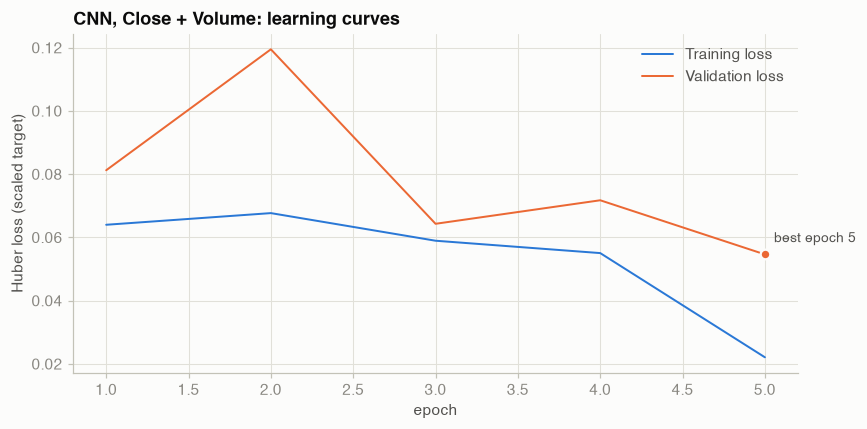

In [12]:
import json

for model_name in ["gru", "cnn"]:
    history_path = PROJECT_ROOT / "artifacts" / f"{model_name}_close_volume_price-target" / "history.json"

    with open(history_path) as f:
        history = json.load(f)

    plotting.plot_history(
        history,
        f"{model_name.upper()}, Close + Volume: learning curves"
    )
    plt.show()

/var/folders/rz/kl765gcx7y9b0z5q2w_cz2lh0000gn/T/ipykernel_31618/3312032582.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0, 0].legend(loc="upper right")


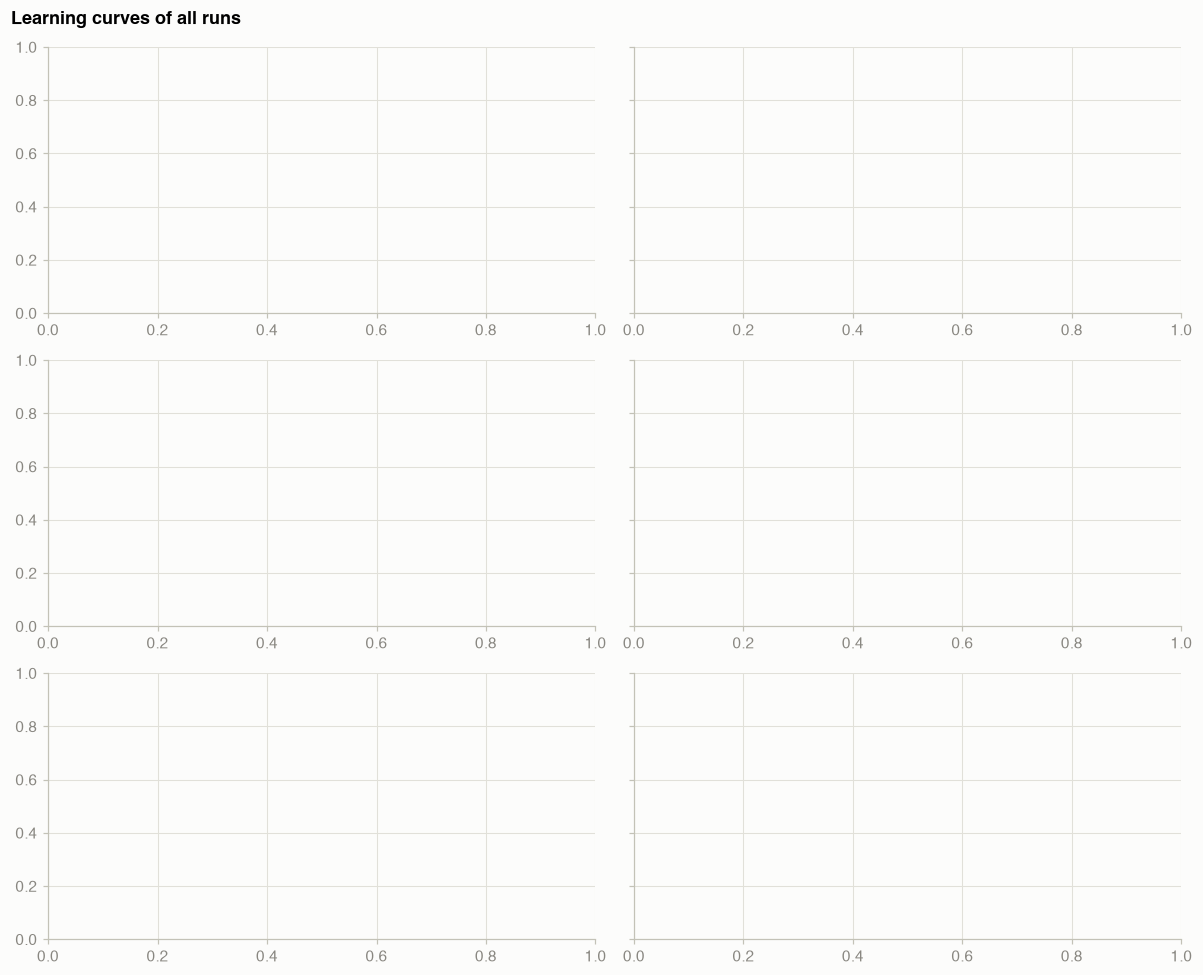

In [13]:
# Small multiples: one panel per run (rows = architecture, columns = feature set), same y-axis for comparison.
fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharey=True)
for ax, (name, result) in zip(axes.ravel(), results.items()):
    ax.plot(result.history["loss"], color=plotting.SERIES[0], label="Training loss")
    ax.plot(result.history["val_loss"], color=plotting.SERIES[1], label="Validation loss")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("epoch")
axes[0, 0].legend(loc="upper right")
fig.suptitle("Learning curves of all runs", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plotting.save_figure(fig, "learning_curves_all_runs.png")
plt.show()

In [14]:
import json
from pathlib import Path

rows = []

for model_name in ["cnn", "lstm", "gru"]:
    folder = PROJECT_ROOT / "artifacts" / f"{model_name}_close_volume_price-target"

    with open(folder / "metadata.json") as f:
        metadata = json.load(f)

    rows.append({
        "run": model_name.upper(),
        "parameters": metadata.get("n_parameters"),
        "epochs run": metadata.get("epochs_run"),
        "best epoch": metadata.get("best_epoch"),
        "best val loss": metadata.get("best_val_loss"),
        "train seconds": metadata.get("train_seconds")
    })

summary = pd.DataFrame(rows).set_index("run")
summary = summary.sort_values("best val loss")

summary.round(4)

,parameters,epochs run,best epoch,best val loss,train seconds
run,,,,,
GRU,13121,5,4,0.0188,3.5
LSTM,17217,5,5,0.0523,3.2
CNN,769,5,5,0.0546,0.7


All runs predict the same target with the same target scaler, so their validation losses are directly comparable. 
Differences in the 3rd or 4th decimal could be noise and re-running with another `SEED` may reorder them.

The loss is measured on *scaled returns*, which is hard to interpret. The next notebook converts predictions back to **dollars** and compares them with the baselines.


Next: [`04_evaluation.ipynb`](04_evaluation.ipynb)